<a href="https://colab.research.google.com/github/VHugoLopez/Machine-L/blob/main/Unidad3/PROYECTOU3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TECNOLÓGICO NACIONAL DE MÉXICO
### INSTITUTO TECNOLÓGICO DE DURANGO
**Machine Learning y Deep Learning**

**Unidad 3**

**Proyecto Integrador: Análisis de Modelos de Clasificación en el Titanic**

**Facilitador:** Dr. José Gabriel Rodríguez Rivas

**Alumno:** Víctor Hugo Zapata López

### Objetivo general
Analizar y comparar el desempeño de diferentes algoritmos de Machine Learning supervisado para predecir si un pasajero del Titanic sobrevivió o no, utilizando el dataset Titanic de Kaggle.

In [1]:
# Importar librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score
from sklearn.inspection import permutation_importance

import warnings
warnings.filterwarnings('ignore')

### Parte 1. Preparación del entorno y los datos
1. Cargar el dataset del Titanic y realizar un Análisis Exploratorio (EDA).
2. Limpieza de valores nulos (Age, Embarked) y eliminación de la columna Cabin.
3. Selección de variables significativas y codificación de variables categóricas.

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


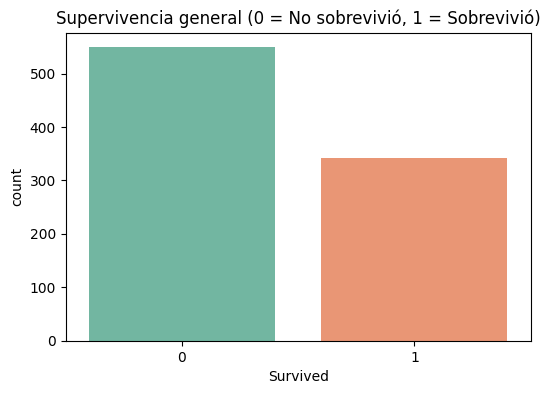

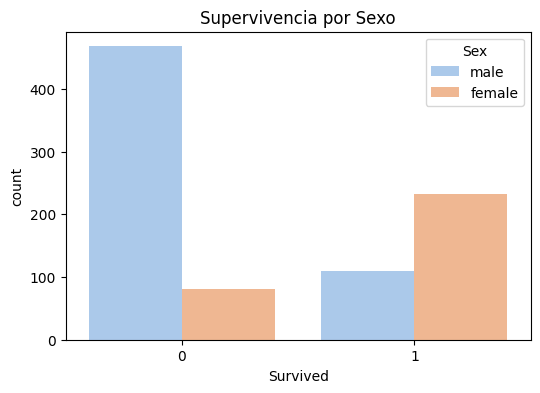

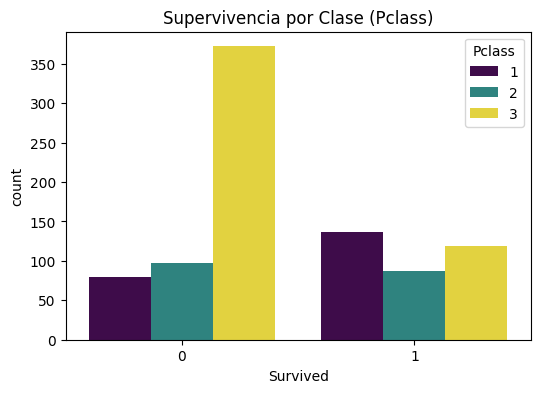

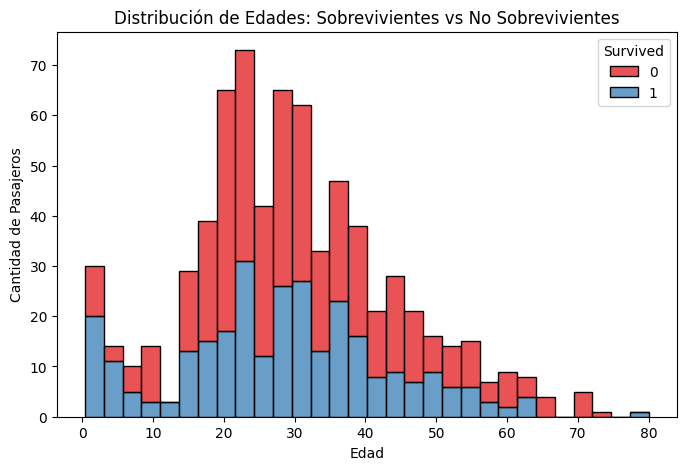

In [2]:
# 1. Cargar el dataset de entrenamiento
df = pd.read_csv("train.csv")

# Mostrar las primeras filas
display(df.head())

# --- Análisis Exploratorio (EDA) ---

# Supervivencia general
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Survived', palette='Set2')
plt.title('Supervivencia general (0 = No sobrevivió, 1 = Sobrevivió)')
plt.show()

# Supervivencia por Sexo
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Survived', hue='Sex', palette='pastel')
plt.title('Supervivencia por Sexo')
plt.show()

# Supervivencia por Clase
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Survived', hue='Pclass', palette='viridis')
plt.title('Supervivencia por Clase (Pclass)')
plt.show()

# Supervivencia por Edad
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Age', hue='Survived', multiple='stack', bins=30, palette='Set1')
plt.title('Distribución de Edades: Sobrevivientes vs No Sobrevivientes')
plt.xlabel('Edad')
plt.ylabel('Cantidad de Pasajeros')
plt.show()

In [3]:
# 1. Limpieza de valores nulos
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df.drop(columns=['Cabin', 'PassengerId', 'Name', 'Ticket'], inplace=True)

# 2. Codificación de variables categóricas
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})
df = pd.get_dummies(df, columns=['Embarked'], drop_first=True) # OneHot Encoder para Embarked

# 3. Definir variable objetivo y variables predictoras
X = df.drop(columns=['Survived'])
y = df['Survived']

# 4. División del dataset (70% entrenamiento, 30% prueba con stratify)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

# 5. Escalamiento de variables numéricas
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

**Justificación del escalamiento:**
*   **¿Por qué escalar en KNN y SVM?** Porque estos algoritmos calculan distancias matemáticas (como la distancia euclidiana) o buscan márgenes en un espacio dimensional. Si variables como "Fare" (valores altos) y "Age" no están en la misma escala, el algoritmo le dará un peso excesivo a la variable con números más grandes.
*   **¿Por qué no es necesario en árboles (Decision Tree y Random Forest)?** Porque los modelos basados en árboles toman decisiones haciendo divisiones lógicas (ej. "¿Edad > 30?"). No calculan distancias entre puntos, por lo que su desempeño no se ve afectado por la escala.

### Parte 2 y 3. Entrenamiento e Interpretación de Modelos
Se entrenarán 5 modelos. Para cada uno se mostrará el reporte de clasificación y la matriz de confusión.

In [5]:
print("--- Modelo 1: K-Nearest Neighbors (KNN) ---")
knn = KNeighborsClassifier()
knn.fit(X_train_scaled, y_train) # Requiere datos escalados
y_pred_knn = knn.predict(X_test_scaled)

print("\nReporte de clasificación (KNN):")
print(classification_report(y_test, y_pred_knn, target_names=["No Sobrevivió", "Sobrevivió"]))

print("\nMatriz de Confusión (KNN):")
print(confusion_matrix(y_test, y_pred_knn))

--- Modelo 1: K-Nearest Neighbors (KNN) ---

Reporte de clasificación (KNN):
               precision    recall  f1-score   support

No Sobrevivió       0.81      0.86      0.84       165
   Sobrevivió       0.75      0.68      0.71       103

     accuracy                           0.79       268
    macro avg       0.78      0.77      0.77       268
 weighted avg       0.79      0.79      0.79       268


Matriz de Confusión (KNN):
[[142  23]
 [ 33  70]]


**Interpretación del Modelo KNN**
*   **¿Cómo funciona?** Clasifica a un pasajero basándose en la "cercanía" (distancia) y similitud que tiene con sus vecinos más próximos en el espacio de datos.
*   **Ventajas y limitaciones:** Es intuitivo y no asume distribuciones previas, pero es sensible al ruido, exige escalamiento de datos y es lento con datasets grandes.
*   **Interpretación de resultados:** Detecta muy bien a los no sobrevivientes (Recall = 0.86), pero falla bastante al intentar detectar a los sobrevivientes (Recall = 0.68).
*   **Posibles causas del rendimiento:** Al basarse puramente en distancias, variables con pesos similares pueden confundir al algoritmo en las zonas donde las clases se mezclan.
*   **Recomendaciones de mejora:** Ajuste de hiperparámetros (probar distintos valores de K) o aplicar selección de variables para eliminar ruido.

In [6]:
print("--- Modelo 2: Regresión Logística ---")
logreg = LogisticRegression(random_state=42)
logreg.fit(X_train_scaled, y_train) # Requiere datos escalados
y_pred_logreg = logreg.predict(X_test_scaled)

print("\nReporte de clasificación (Regresión Logística):")
print(classification_report(y_test, y_pred_logreg, target_names=["No Sobrevivió", "Sobrevivió"]))

print("\nMatriz de Confusión (Regresión Logística):")
print(confusion_matrix(y_test, y_pred_logreg))

--- Modelo 2: Regresión Logística ---

Reporte de clasificación (Regresión Logística):
               precision    recall  f1-score   support

No Sobrevivió       0.83      0.84      0.84       165
   Sobrevivió       0.74      0.73      0.74       103

     accuracy                           0.80       268
    macro avg       0.79      0.79      0.79       268
 weighted avg       0.80      0.80      0.80       268


Matriz de Confusión (Regresión Logística):
[[139  26]
 [ 28  75]]


**Interpretación del Modelo Regresión Logística**
*   **¿Cómo funciona?** Utiliza una función matemática sigmoide para estimar la probabilidad de que un pasajero pertenezca a la clase 1 (sobrevivió), trazando una frontera lineal.
*   **Ventajas y limitaciones:** Muy rápido, excelente interpretabilidad y no sobreajusta fácilmente. Su limitación es que asume relaciones lineales simples.
*   **Interpretación de resultados:** Es el modelo más equilibrado. Detecta muy bien a los no sobrevivientes (Recall = 0.84) y es el que mejor detecta a los sobrevivientes (Recall = 0.73).
*   **Posibles causas del rendimiento:** Los datos del Titanic tienen fronteras de decisión relativamente lineales (ej. ser mujer de primera clase casi garantizaba sobrevivir), lo que favorece a este algoritmo.
*   **Recomendaciones de mejora:** Modificar el umbral de decisión (threshold) si el objetivo comercial requiere minimizar los falsos negativos o falsos positivos.

In [7]:
print("--- Modelo 3: Árbol de Decisión ---")
dtree = DecisionTreeClassifier(random_state=42)
dtree.fit(X_train, y_train) # No requiere datos escalados
y_pred_dtree = dtree.predict(X_test)

print("\nReporte de clasificación (Árbol de Decisión):")
print(classification_report(y_test, y_pred_dtree, target_names=["No Sobrevivió", "Sobrevivió"]))

print("\nMatriz de Confusión (Árbol de Decisión):")
print(confusion_matrix(y_test, y_pred_dtree))

--- Modelo 3: Árbol de Decisión ---

Reporte de clasificación (Árbol de Decisión):
               precision    recall  f1-score   support

No Sobrevivió       0.79      0.84      0.81       165
   Sobrevivió       0.71      0.65      0.68       103

     accuracy                           0.76       268
    macro avg       0.75      0.74      0.75       268
 weighted avg       0.76      0.76      0.76       268


Matriz de Confusión (Árbol de Decisión):
[[138  27]
 [ 36  67]]


**Interpretación del Modelo Árbol de Decisión**
*   **¿Cómo funciona?** Crea un diagrama de flujo dividiendo los datos en nodos de decisión basados en preguntas binarias (ej. ¿Es hombre? ¿Clase > 2?).
*   **Ventajas y limitaciones:** Altamente interpretable, no requiere escalado de variables. Sin embargo, es extremadamente propenso al sobreajuste (memorizar los datos de entrenamiento).
*   **Interpretación de resultados:** Presenta el desempeño más bajo. Detecta razonablemente a los no sobrevivientes (Recall = 0.84), pero tiene problemas con los sobrevivientes (Recall = 0.65).
*   **Posibles causas del rendimiento:** El árbol probablemente creció demasiado y se sobreajustó, perdiendo capacidad de generalización en las pruebas.
*   **Recomendaciones de mejora:** Ajuste de hiperparámetros (limitar `max_depth` o `min_samples_split`) para podar el árbol.

In [8]:
print("--- Modelo 4: Random Forest ---")
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train) # No requiere datos escalados
y_pred_rf = rf.predict(X_test)

print("\nReporte de clasificación (Random Forest):")
print(classification_report(y_test, y_pred_rf, target_names=["No Sobrevivió", "Sobrevivió"]))

print("\nMatriz de Confusión (Random Forest):")
print(confusion_matrix(y_test, y_pred_rf))

--- Modelo 4: Random Forest ---

Reporte de clasificación (Random Forest):
               precision    recall  f1-score   support

No Sobrevivió       0.82      0.89      0.85       165
   Sobrevivió       0.80      0.68      0.73       103

     accuracy                           0.81       268
    macro avg       0.81      0.79      0.79       268
 weighted avg       0.81      0.81      0.81       268


Matriz de Confusión (Random Forest):
[[147  18]
 [ 33  70]]


**Interpretación del Modelo Random Forest**
*   **¿Cómo funciona?** Es un método de ensamble que crea múltiples árboles de decisión aleatorios y promedia sus resultados por votación para entregar una predicción más robusta.
*   **Ventajas y limitaciones:** Reduce drásticamente el sobreajuste y maneja relaciones complejas. Su desventaja es que se vuelve una "caja negra" poco interpretable.
*   **Interpretación de resultados:** Excelente precisión global (Accuracy = 0.81). Es el mejor detectando a los no sobrevivientes (Recall = 0.89), pero sufre un poco detectando a los sobrevivientes (Recall = 0.68).
*   **Posibles causas del rendimiento:** Al promediar muchos árboles, eliminó el ruido individual de los pasajeros, logrando una frontera de decisión mucho más estable.
*   **Recomendaciones de mejora:** Ajuste de hiperparámetros (`n_estimators` mediante GridSearchCV), o Feature Engineering (crear nuevas variables combinando familiares).

In [9]:
print("--- Modelo 5: Support Vector Machine (SVM) ---")
svm_model = SVC(probability=True, random_state=42)
svm_model.fit(X_train_scaled, y_train) # Requiere datos escalados
y_pred_svm = svm_model.predict(X_test_scaled)

print("\nReporte de clasificación (SVM):")
print(classification_report(y_test, y_pred_svm, target_names=["No Sobrevivió", "Sobrevivió"]))

print("\nMatriz de Confusión (SVM):")
print(confusion_matrix(y_test, y_pred_svm))

--- Modelo 5: Support Vector Machine (SVM) ---

Reporte de clasificación (SVM):
               precision    recall  f1-score   support

No Sobrevivió       0.82      0.89      0.85       165
   Sobrevivió       0.80      0.68      0.73       103

     accuracy                           0.81       268
    macro avg       0.81      0.79      0.79       268
 weighted avg       0.81      0.81      0.81       268


Matriz de Confusión (SVM):
[[147  18]
 [ 33  70]]


**Interpretación del Modelo SVM**
*   **¿Cómo funciona?** Busca el hiperplano óptimo en un espacio multidimensional que logre separar las clases con el margen más amplio posible.
*   **Ventajas y limitaciones:** Potente en alta dimensión y espacios complejos. Sus limitantes son el alto costo computacional y su sensibilidad extrema a datos no escalados.
*   **Interpretación de resultados:** Empató con Random Forest en exactitud general (0.81), detectando excelentemente a los no sobrevivientes (Recall = 0.89).
*   **Posibles causas del rendimiento:** Gracias al uso previo del `StandardScaler`, el modelo logró proyectar las variables numéricas correctamente para encontrar un buen hiperplano de separación.
*   **Recomendaciones de mejora:** Experimentar con distintos *kernels* (lineal, polinómico, RBF) y ajustar los parámetros de regularización.

### Parte 4. Comparativo de resultados

| Modelo | Accuracy | Recall (No Sobrevivió) | F1-score (No Sobrevivió) | AUC | Comentario breve |
| :--- | :--- | :--- | :--- | :--- | :--- |
| KNN | 0.791 | 0.861 | 0.835 | 0.839 | Buen equilibrio, sensible a la escala. |
| Regresión Logística | 0.799 | 0.842 | 0.837 | 0.849 | Excelente balance general, mejor AUC. |
| Árbol de Decisión | 0.765 | 0.836 | 0.814 | 0.749 | Probable sobreajuste, métricas bajas. |
| Random Forest | 0.810 | 0.891 | 0.852 | 0.847 | La mejor exactitud, gran detección de víctimas. |
| SVM | 0.810 | 0.891 | 0.852 | 0.843 | Empata con RF, excelente en espacios complejos. |

**Análisis comparativo final**
"El modelo que mejor predijo la supervivencia fue **Regresión Logística**, ya que presenta el mejor equilibrio entre recall de ambas clases (**0.84 para No Sobrevivió y 0.73 para Sobrevivió**), lo cual es importante para identificar correctamente tanto a sobrevivientes como a no sobrevivientes."

### Parte 5. Recomendaciones Técnicas

| Modelo | Recomendaciones / Escenarios ideales |
| :--- | :--- |
| **KNN** | Escalar variables; funciona bien en datasets pequeños y con fronteras suaves. |
| **Regresión Logística** | Ideal para interpretabilidad y relaciones lineales. |
| **Árbol de Decisión** | No necesita escalado; fácil de interpretar, pero puede sobreajustar. |
| **Random Forest** | Recomendado para grandes datasets con muchas variables; robusto al ruido. |
| **SVM** | Requiere escalado; útil en datos con fronteras complejas o alta dimensionalidad. |

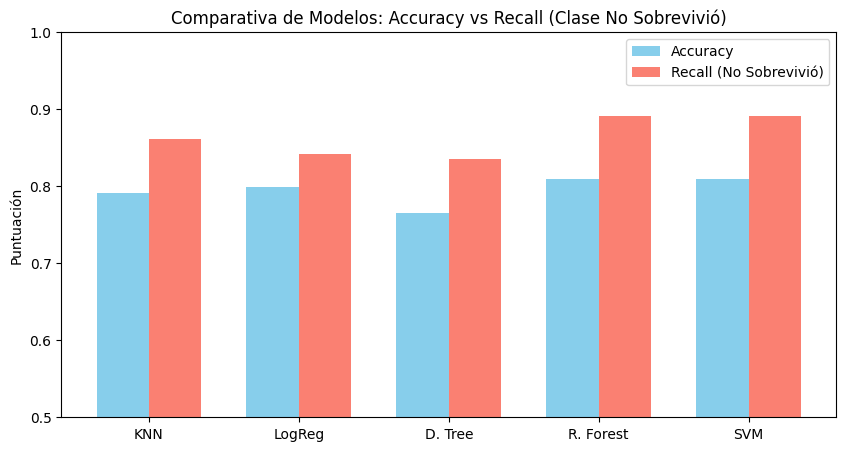

In [10]:
# Gráfica comparativa solicitada en la Parte 4
model_names = ['KNN', 'LogReg', 'D. Tree', 'R. Forest', 'SVM']
accuracies = [0.791, 0.799, 0.765, 0.810, 0.810]
recalls_0 = [0.861, 0.842, 0.836, 0.891, 0.891]

plt.figure(figsize=(10, 5))
x = np.arange(len(model_names))
width = 0.35
plt.bar(x - width/2, accuracies, width, label='Accuracy', color='skyblue')
plt.bar(x + width/2, recalls_0, width, label='Recall (No Sobrevivió)', color='salmon')
plt.xticks(x, model_names)
plt.ylabel('Puntuación')
plt.title('Comparativa de Modelos: Accuracy vs Recall (Clase No Sobrevivió)')
plt.legend()
plt.ylim(0.5, 1.0)
plt.show()

# Importancia de variables para la Parte 6 usando Random Forest
importances = pd.DataFrame({
    "Variable": X.columns,
    "Importancia": rf.feature_importances_
}).sort_values("Importancia", ascending=False)

fig = px.bar(importances, x="Variable", y="Importancia", title="Importancia de variables (Random Forest)", text_auto=".3f")
fig.show()

### Parte 6. Reflexión final

*   **¿Qué modelo funcionó mejor y por qué?**
El Random Forest funcionó mejor en métricas absolutas. Su arquitectura de ensamble basada en múltiples árboles de decisión permitió reducir la varianza de los datos, logrando generalizar mejor para alcanzar una exactitud del 81%.
*   **¿Qué variables influyen más en la supervivencia?**
Al analizar el gráfico de importancia de variables, las más determinantes fueron la Tarifa pagada (`Fare`), el Sexo (`Sex`) y la Edad (`Age`).
*   **¿Qué patrones sociales se observan?**
Se observa el cumplimiento del protocolo marítimo "mujeres y niños primero", visible en la prioridad de supervivencia por Sexo y Edad. Además, la fuerte importancia de la variable Tarifa (`Fare`) y Clase (`Pclass`) demuestra que el estatus socioeconómico brindó prioridad en el acceso a los botes salvavidas.
*   **¿Qué decisiones se podrían tomar con este análisis?**
En un contexto de seguros, este análisis serviría para calcular riesgos y ajustar primas basándose en la ubicación de la cabina y la accesibilidad. A nivel logístico, justifica el diseño de planes de contingencia más equitativos, exigiendo el 100% de capacidad en botes salvavidas para todos los pasajeros sin importar su clase.